In [1]:
import duckdb, pandas as pd

# Hand-validated values (validation_sheet.csv), converted to Mt
validated = pd.DataFrame([
    # company,       crude_mt, scope1_mt, scope2_mt, year,     note
    ("SSAB",          7.536,    9.839,     0.896,    "2025",    "kt in report"),
    ("thyssenkrupp",  9.3,      19.8,      1.2,      "2024/25", "group-wide Scope 1+2; crude steel incl. deliveries to HKM"),
    ("Nucor",        21.0,      4.3,       None,     "2024",    "SASB index; Scope 1 unit not printed (assumed t CO2e); no Scope 2 disclosed"),
], columns=["company", "crude_mt", "scope1_mt", "scope2_mt", "year", "note"])

validated["intensity_t_per_t"] = (validated.scope1_mt + validated.scope2_mt.fillna(0)) / validated.crude_mt
validated["intensity_basis"] = validated.scope2_mt.apply(lambda s: "Scope 1+2" if pd.notna(s) else "Scope 1 only")

con = duckdb.connect("../db/steel.duckdb", read_only=True)
gist = con.execute("SELECT company, crude_mtpa AS gist_capacity_mtpa, eaf_share FROM company_benchmark").df()
con.close()

bench = validated.merge(gist, on="company", how="left")
bench["eaf_share_pct"] = (100 * bench.eaf_share).round(0)
bench["utilisation_pct"] = (100 * bench.crude_mt / bench.gist_capacity_mtpa).round(0)
bench.to_csv("../data/extracted/benchmark_3_companies.csv", index=False)

print(bench[["company", "eaf_share_pct", "intensity_t_per_t", "intensity_basis",
             "crude_mt", "gist_capacity_mtpa", "utilisation_pct", "year"]].round(2).to_string(index=False))

     company  eaf_share_pct  intensity_t_per_t intensity_basis  crude_mt  gist_capacity_mtpa  utilisation_pct    year
        SSAB           28.0               1.42       Scope 1+2      7.54                8.86             85.0    2025
thyssenkrupp            2.0               2.26       Scope 1+2      9.30               11.32             82.0 2024/25
       Nucor          100.0               0.20    Scope 1 only     21.00               26.77             78.0    2024


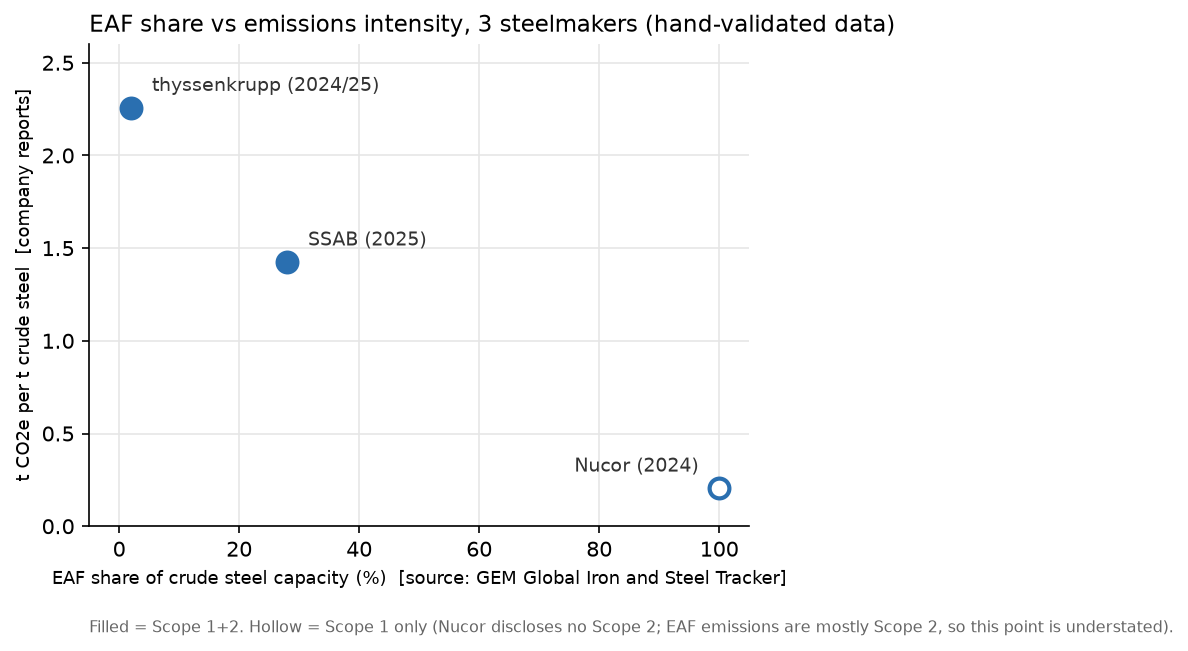

In [2]:
import matplotlib.pyplot as plt
from pathlib import Path

Path("../charts").mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)
color = "#2a6fb0"

for _, r in bench.iterrows():
    full = r.intensity_basis == "Scope 1+2"
    ax.scatter(r.eaf_share_pct, r.intensity_t_per_t, s=90, zorder=3,
               facecolor=color if full else "white", edgecolor=color, linewidth=2)
    right_edge = r.eaf_share_pct > 90
    ax.annotate(f"{r.company} ({r.year})", (r.eaf_share_pct, r.intensity_t_per_t),
                xytext=(-10 if right_edge else 10, 8), textcoords="offset points",
                ha="right" if right_edge else "left", fontsize=9, color="#333333")

ax.set_xlim(-5, 105)
ax.set_ylim(0, 2.6)
ax.set_xlabel("EAF share of crude steel capacity (%)  [source: GEM Global Iron and Steel Tracker]", fontsize=8.5)
ax.set_ylabel("t CO2e per t crude steel  [company reports]", fontsize=8.5)
ax.set_title("EAF share vs emissions intensity, 3 steelmakers (hand-validated data)",
             loc="left", fontsize=11)
ax.grid(color="#e6e6e6", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.text(0, -0.22, "Filled = Scope 1+2. Hollow = Scope 1 only (Nucor discloses no Scope 2; "
        "EAF emissions are mostly Scope 2, so this point is understated).",
        transform=ax.transAxes, fontsize=7.5, color="#666666")

plt.tight_layout()
plt.savefig("../charts/eaf_vs_intensity.png", bbox_inches="tight")
plt.show()

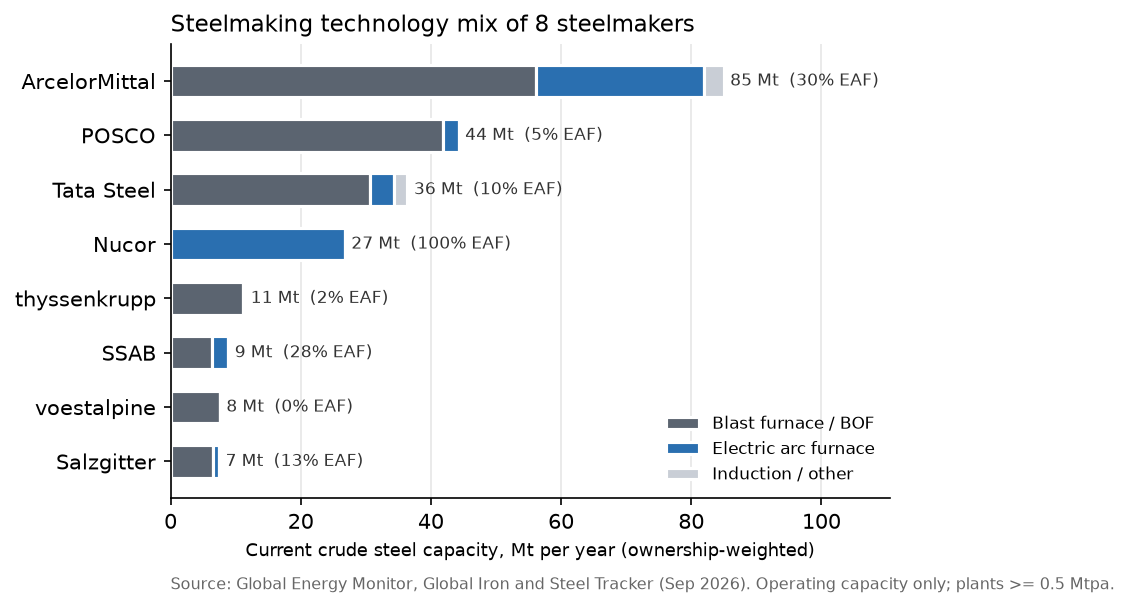

      company  bof  eaf  other  total
   Salzgitter  6.5  1.0    0.0    7.5
  voestalpine  7.6  0.0    0.0    7.6
         SSAB  6.4  2.5    0.0    8.9
 thyssenkrupp 11.1  0.2    0.0   11.3
        Nucor  0.0 26.8    0.0   26.8
   Tata Steel 30.6  3.7    2.1   36.4
        POSCO 41.9  2.4    0.0   44.3
ArcelorMittal 56.1 25.9    3.0   85.0


In [3]:
import duckdb, pandas as pd
import matplotlib.pyplot as plt

con = duckdb.connect("../db/steel.duckdb", read_only=True)
mix = con.execute("""
    SELECT m.company,
           SUM(COALESCE(c.nominal_bof_steel_capacity_ttpa, 0) * pp.share) / 1000 AS bof,
           SUM(COALESCE(c.nominal_eaf_steel_capacity_ttpa, 0) * pp.share) / 1000 AS eaf,
           SUM((COALESCE(c.nominal_if_steel_capacity_ttpa, 0)
              + COALESCE(c.other_unspecified_steel_capacity_ttpa, 0)) * pp.share) / 1000 AS other
    FROM capacities c
    JOIN plant_parents pp USING (gem_plant_id)
    JOIN company_map m USING (parent_id)
    WHERE c.is_current
    GROUP BY m.company
""").df()
con.close()

mix["total"] = mix[["bof", "eaf", "other"]].sum(axis=1)
mix = mix.sort_values("total")

fig, ax = plt.subplots(figsize=(7, 4.2), dpi=150)
parts = [("bof", "Blast furnace / BOF", "#5b6470"),
         ("eaf", "Electric arc furnace", "#2a6fb0"),
         ("other", "Induction / other", "#c9ced6")]
left = 0
for col, label, color in parts:
    ax.barh(mix.company, mix[col], left=left, color=color, label=label,
            edgecolor="white", linewidth=1.5, height=0.6)
    left = left + mix[col]
for y, (total, eaf) in enumerate(zip(mix.total, mix.eaf)):
    ax.text(total + 1, y, f"{total:.0f} Mt  ({100 * eaf / total:.0f}% EAF)",
            va="center", fontsize=8, color="#333333")

ax.set_xlabel("Current crude steel capacity, Mt per year (ownership-weighted)", fontsize=8.5)
ax.set_title("Steelmaking technology mix of 8 steelmakers", loc="left", fontsize=11)
ax.set_xlim(0, mix.total.max() * 1.3)
ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.text(0, -0.2, "Source: Global Energy Monitor, Global Iron and Steel Tracker (Sep 2026). "
        "Operating capacity only; plants >= 0.5 Mtpa.", transform=ax.transAxes, fontsize=7.5, color="#666666")

plt.tight_layout()
plt.savefig("../charts/capacity_mix.png", bbox_inches="tight")
plt.show()
print(mix.round(1).to_string(index=False))